# Empirical Retrieval Benchmark: Exploratory Analysis & Visualizations

**Corpus:** 17 NCERT STEM Textbooks (Classes 10–12, 169 chapters, 4,429 parsed chunks)  
**Benchmark Queries:** 282 natural student queries across clean (prose) and fragmented (math) tiers  
**Hardware:** Single-threaded CPU (AMD Ryzen / Linux) serial latency profiling  

This notebook provides the exploratory data analysis, Pareto trade-off curves, and paired statistical significance tests validating our hybrid retrieval architecture.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Set publication plotting aesthetics
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.edgecolor': '#d0d7de',
    'axes.linewidth': 1.2,
    'grid.color': '#eaeef2',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
})

## 1. Benchmark Data Summary

We benchmark 8 retrieval strategies isolating three architectural axes:
1. **Lexical (`bm25`)**: SQLite FTS5 with Porter stemming.
2. **Dense (`vector_parsed`, `vector_raw`)**: Local `bge-small-en-v1.5` embeddings on CPU with ChromaDB HNSW.
3. **Hybrid RRF (`hybrid`)**: Reciprocal Rank Fusion ($k=60$) combining BM25 and dense vectors.
4. **Query Expansion (`expansion_*`)**: Few-shot LLM query rewriting (Gemini 3.7 Flash) appending technical textbook vocabulary.

In [2]:
# Benchmark results from evals/REPORT.md
results = [
    ('bm25', 53.9, 75.5, 81.9, 0.635, 3.5),
    ('vector_parsed', 59.6, 83.3, 90.8, 0.698, 4.9),
    ('vector_raw', 58.9, 84.4, 89.7, 0.693, 4.8),
    ('hybrid', 58.5, 86.9, 92.9, 0.704, 8.9),
    ('expansion_bm25', 71.6, 90.8, 94.3, 0.802, 4563.4),
    ('expansion_vector', 71.3, 90.8, 94.3, 0.800, 4625.3),
    ('expansion_raw', 69.9, 92.2, 95.0, 0.789, 4585.2),
    ('expansion_hybrid', 72.7, 92.9, 95.0, 0.815, 4708.8),
]

print(f"{'Arm':<20} {'Recall@1':>10} {'Recall@5':>10} {'Recall@10':>10} {'MRR':>10} {'Latency (ms)':>15}")
print("-" * 72)
for arm, r1, r5, r10, mrr, lat in results:
    print(f"{arm:<20} {r1:>9.1f}% {r5:>9.1f}% {r10:>9.1f}% {mrr:>10.3f} {lat:>12.1f} ms")

Arm                 Recall@1   Recall@5  Recall@10        MRR    Latency (ms)
------------------------------------------------------------------------
bm25                   53.9%      75.5%      81.9%      0.635          3.5 ms
vector_parsed          59.6%      83.3%      90.8%      0.698          4.9 ms
vector_raw             58.9%      84.4%      89.7%      0.693          4.8 ms
hybrid                 58.5%      86.9%      92.9%      0.704          8.9 ms
expansion_bm25         71.6%      90.8%      94.3%      0.802       4563.4 ms
expansion_vector       71.3%      90.8%      94.3%      0.800       4625.3 ms
expansion_raw          69.9%      92.2%      95.0%      0.789       4585.2 ms
expansion_hybrid       72.7%      92.9%      95.0%      0.815       4708.8 ms


## 2. Latency vs. Recall@5 Pareto Frontier

When selecting a retrieval architecture for interactive applications, evaluating recall in isolation is misleading. The key operational question is **marginal recall per millisecond of latency**.

* **Sub-10ms Sweet Spot (`hybrid`)**: Fusing BM25 and dense embeddings with Reciprocal Rank Fusion ($k=60$) hits **86.9% Recall@5 in 8.9ms on CPU** with $0.00 token cost.
* **The Latency Wall (`expansion_hybrid`)**: Adding an external LLM query rewriter reaches 92.9% Recall@5, but inflates serving latency by **528× (4,709 ms)**.

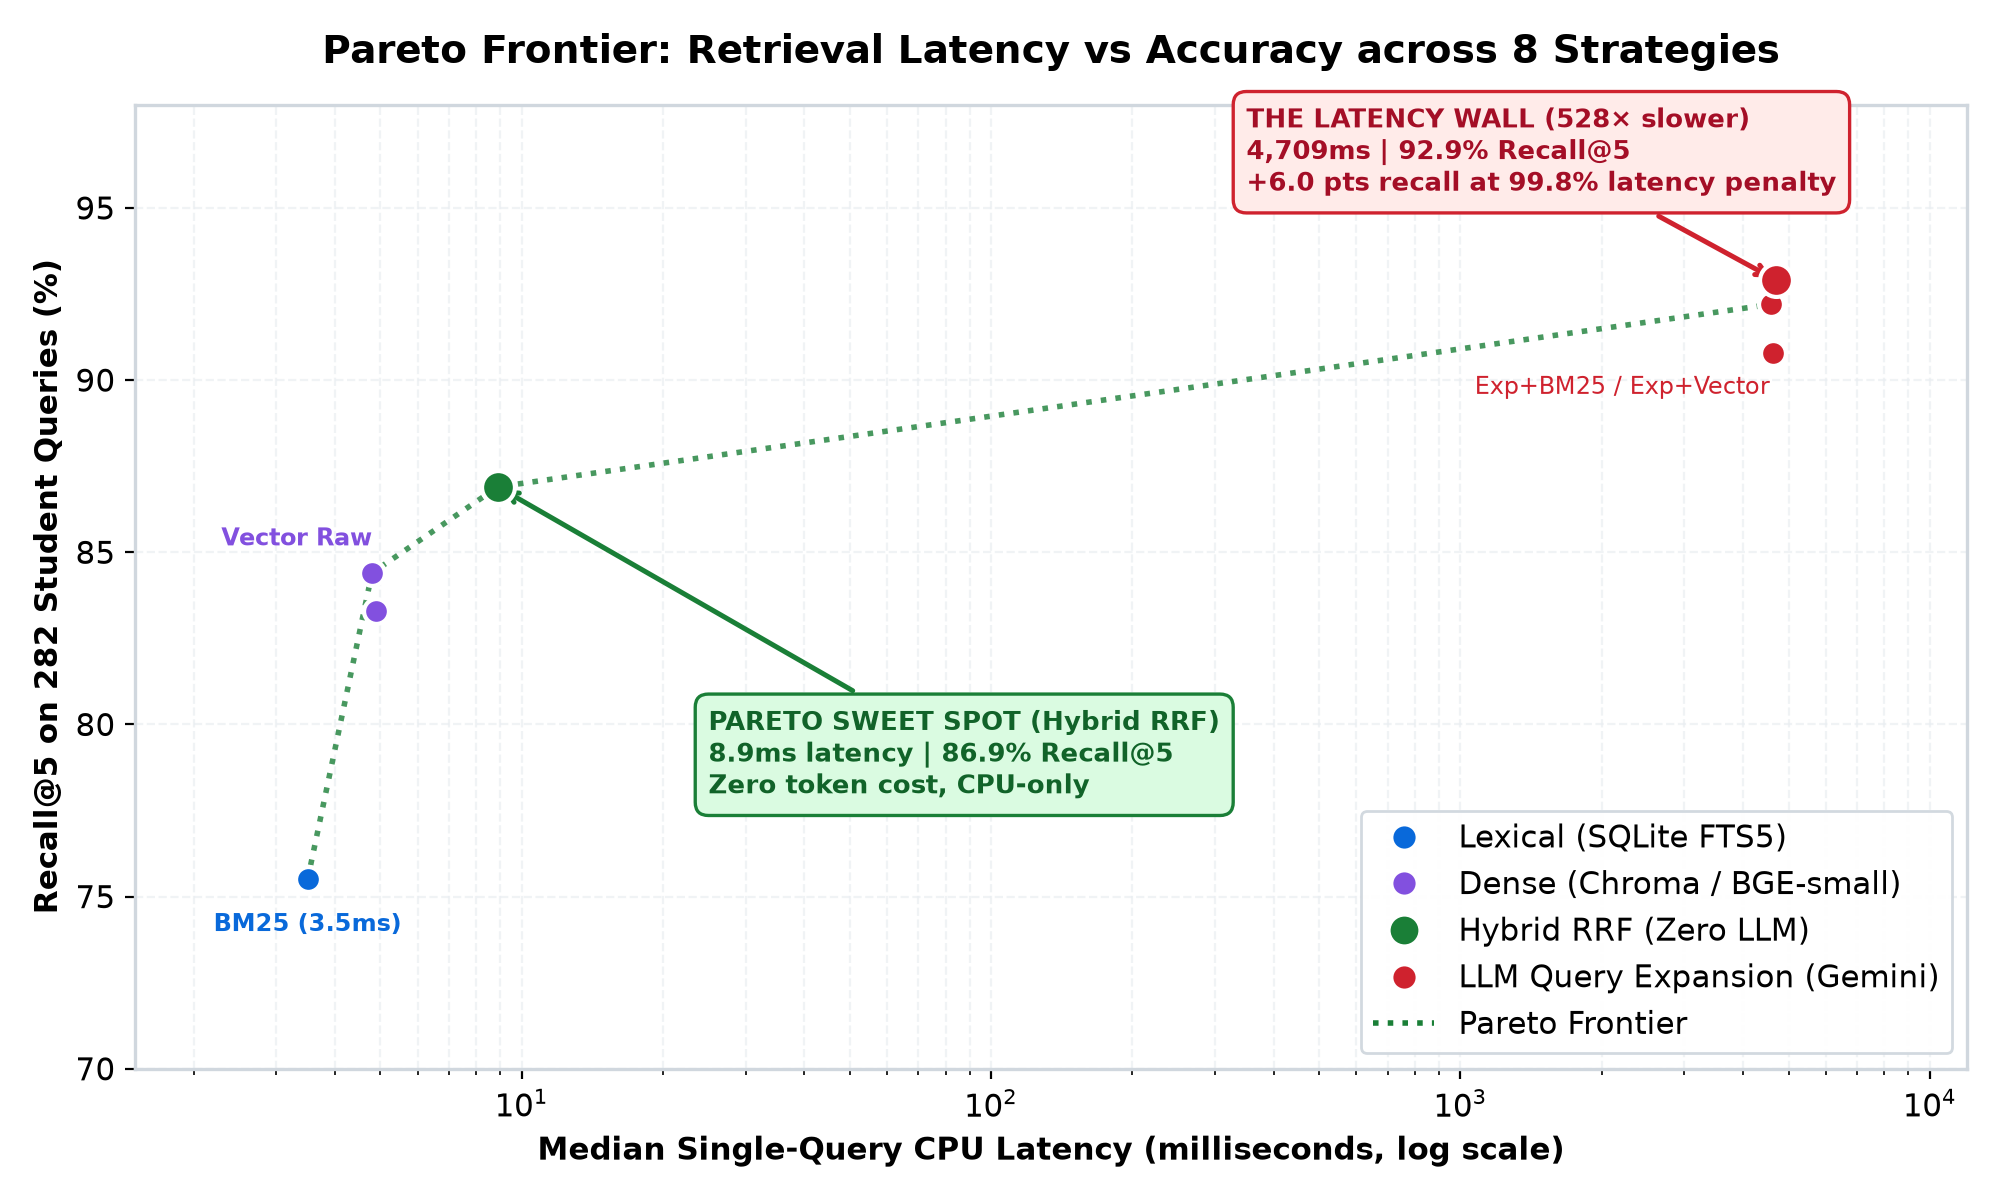

In [3]:
# Visualizing the Pareto Frontier
from evals.generate_charts import plot_pareto_frontier
plot_pareto_frontier()

## 3. Corpus Heterogeneity & Tier Breakdown

PDF extraction quality dramatically alters retrieval mechanics across domains:
* **Clean Tier (13 books, $n=239$):** Continuous prose (Biology, Chemistry, Economics). Dense retrieval significantly outperforms BM25 (+9.6% at R@5).
* **Fragmented Tier (4 books, $n=43$):** Mathematics textbooks where formulas, fractions, and square roots get shredded into 1- or 2-character tokens by PDF extractors. Keyword match retains high utility, while broken equation fragments degrade vector similarity.

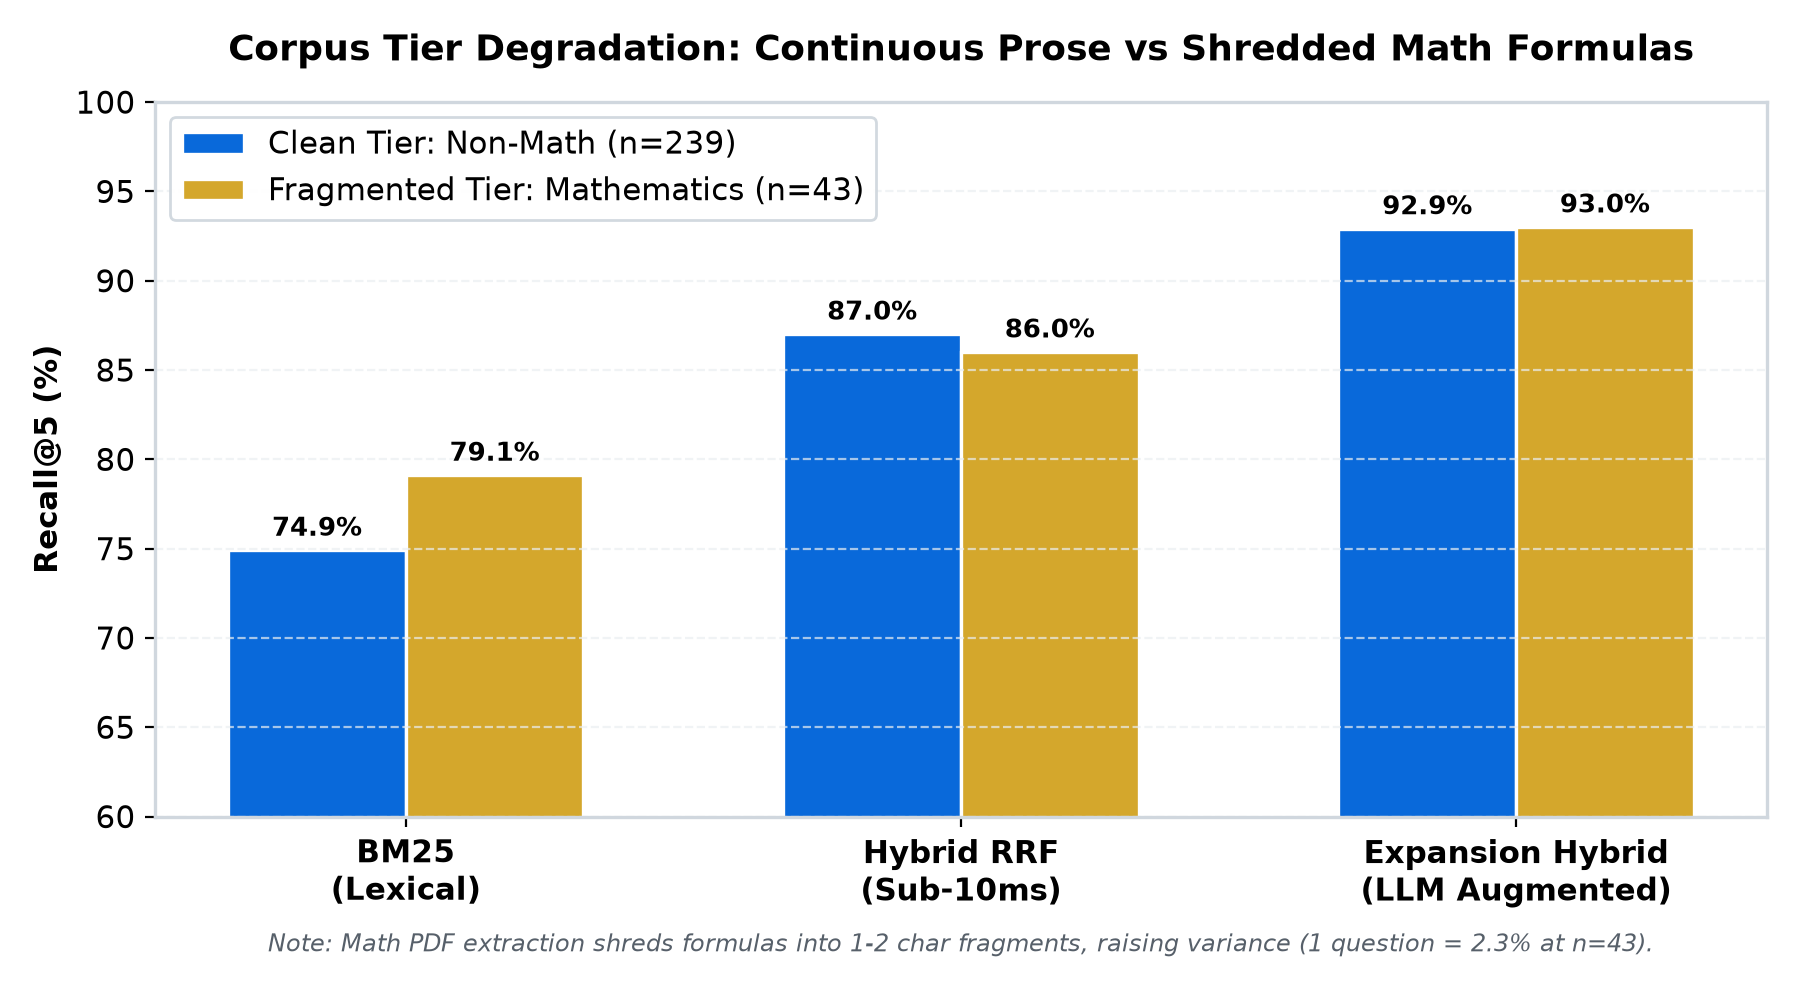

In [4]:
# Visualizing Clean vs Fragmented Tier Performance
from evals.generate_charts import plot_tier_breakdown
plot_tier_breakdown()

## 4. Paired McNemar Significance Testing

Because every retrieval strategy answers the **exact same 282 questions**, standard two-sample independent tests (like Student's t-test or z-test) are invalid. We evaluate discordant pairs (queries where Technique A and Technique B disagree) using **McNemar's test** with continuity correction:

$$\chi^2 = \frac{(|b - c| - 1)^2}{b + c}$$

* **`hybrid` over `bm25`**: +11.3% net gap, 35 wins / 3 losses ($p < 0.0001$, 95% CI [+7.3, +15.4]). **Established.**
* **`expansion_hybrid` over `hybrid`**: +6.0% net gap, 22 wins / 5 losses ($p = 0.0021$, 95% CI [+2.5, +9.6]). **Established.**
* **`vector_parsed` vs `vector_raw`**: -1.1% gap ($p = 0.7003$, 95% CI [-4.7, +2.5]). **Negative Result.**

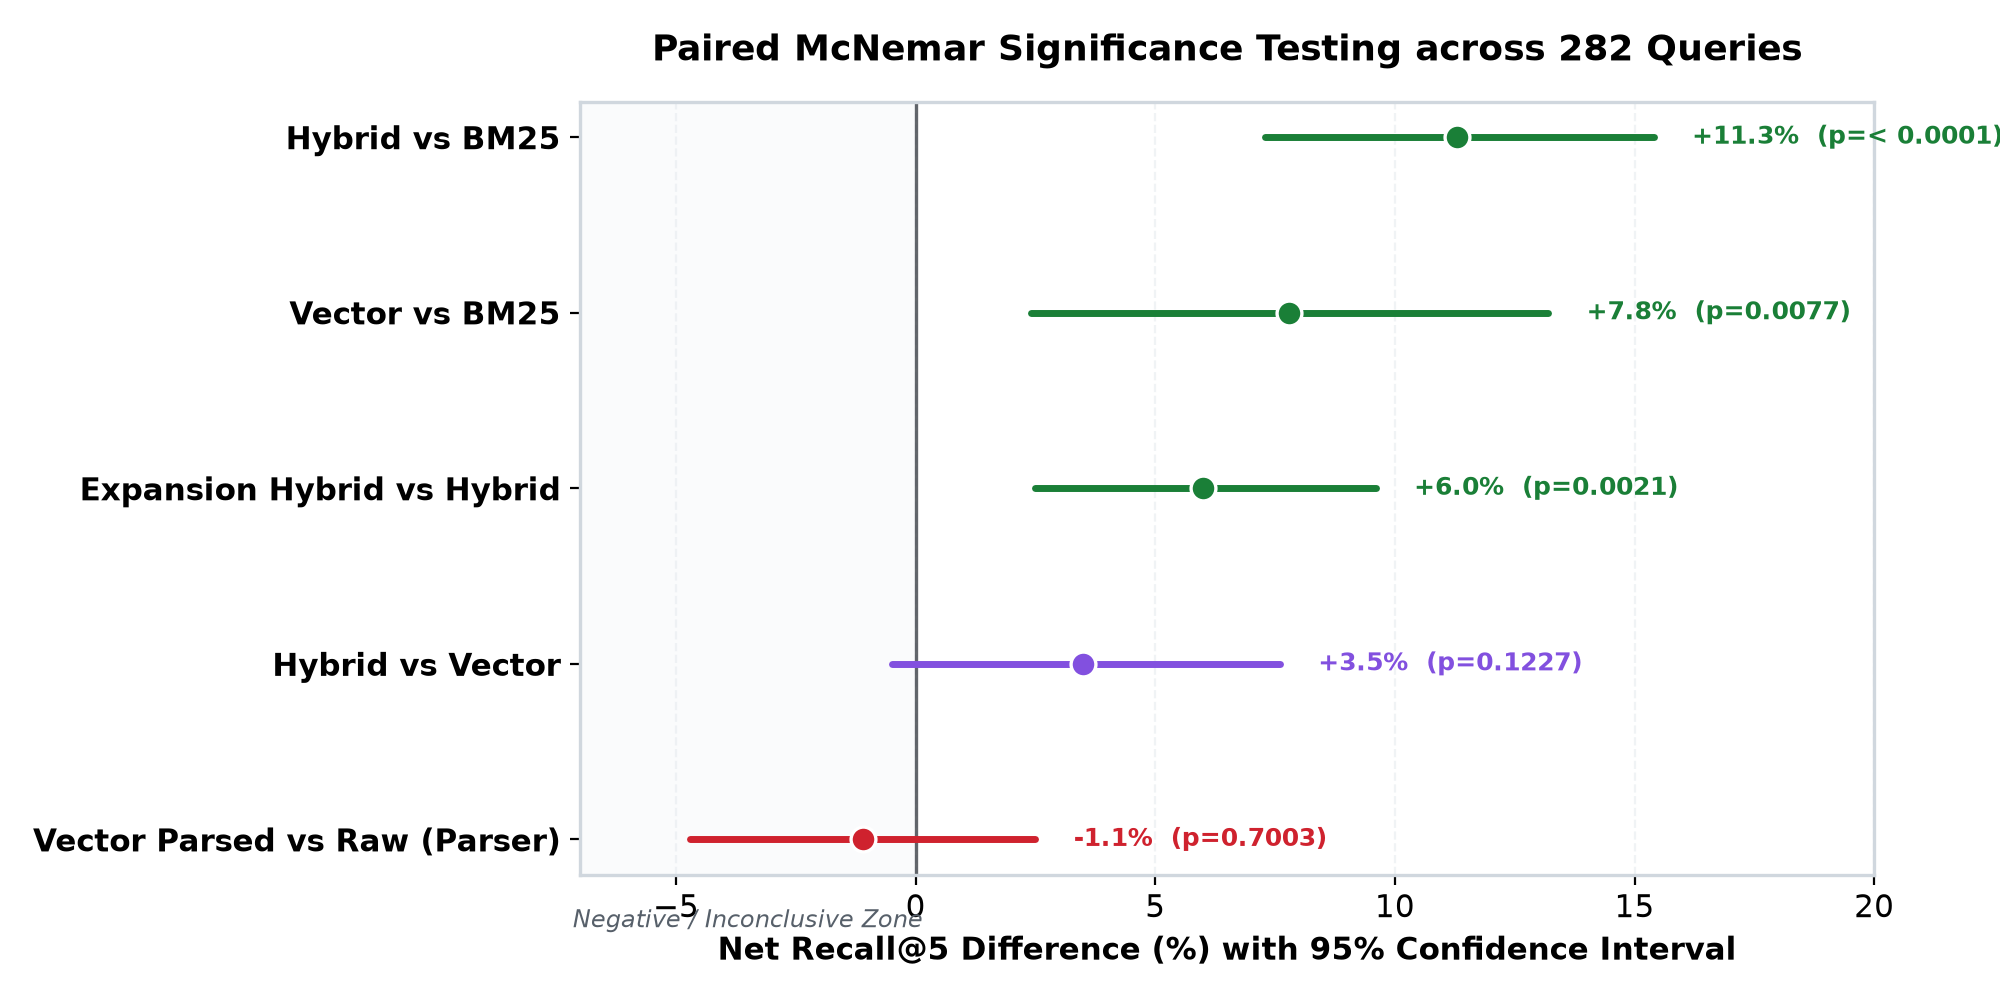

In [5]:
# Visualizing Paired Difference Intervals and Significance
from evals.generate_charts import plot_mcnemar_discordance
plot_mcnemar_discordance()

## 5. Architectural Findings & Takeaways

1. **Reciprocal Rank Fusion on CPU is the Production Champion:** At 8.9ms and 86.9% Recall@5, `hybrid` provides an optimal production balance with zero external API dependencies.
2. **AST Parsing is for Readability, Not Retrieval:** Strict section-aware parsing does not improve recall over blind 512-token sliding windows ($p = 0.7003$) due to boundary truncation of small sections.
3. **Semantic Query Caching:** For workloads requiring 92%+ recall, routing high-frequency queries through a semantic cache of precomputed expansions avoids the 4.7-second latency penalty.